## Normal Distribution

Normal Distribution, also known as Gaussian distribution is one of the most widely assumed distribution in Data Science. A normal distribution has a bell-shaped density curve described by its mean μ and standard deviation σ. The density curve is symmetrical, centered about its mean, with its spread determined by its standard deviation.

The probability distribution function of a normal density curve with mean μ and standard deviation σ at a given point x is given by:

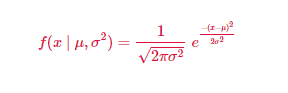

In [4]:
Image.open(os.path.join(dir_path,'NormalDist.PNG'))

### Load GBPUSD data

In [7]:
import yfinance as yf

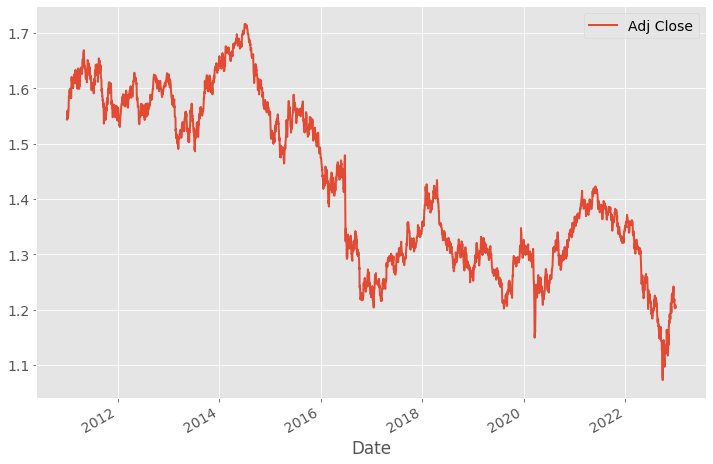

In [76]:
df = yf.download('GBPUSD=X', start='2011-01-01', end='2022-12-31',progress = False)  

df.plot(y= 'Adj Close')
plt.show()

### Calculate Return

In [23]:
df['Return'] = df['Adj Close'].pct_change().fillna(0)

### Calculate Mean & Sigma

In [38]:
mu = np.mean(df['Return'])
sigma = np.std(df['Return'])

mu,sigma

(-6.30337250286831e-05, 0.005653470928220306)

### Calculate Scaled Returns

In [40]:
df['Scaled Return'] = df.Return.apply(lambda x:(x-mu)/sigma)

,Open,High,Low,Close,Adj Close,Volume,Return,Scaled Return
Date,,,,,,,,
2010-12-31,1.543591,1.565803,1.542972,1.543710,1.543710,0,0.000000,0.011150
2011-01-03,1.557608,1.557608,1.543996,1.557244,1.557244,0,0.008767,1.561934
2011-01-04,1.548899,1.564602,1.545595,1.548971,1.548971,0,-0.005313,-0.928623
2011-01-05,1.560014,1.562598,1.545595,1.559795,1.559795,0,0.006988,1.247177
2011-01-06,1.551301,1.556009,1.546814,1.551205,1.551205,0,-0.005507,-0.962897
2011-01-07,1.545308,1.557899,1.541592,1.545094,1.545094,0,-0.003940,-0.685767
2011-01-10,1.554509,1.556759,1.547820,1.554002,1.554002,0,0.005765,1.030942
2011-01-11,1.559041,1.560184,1.551807,1.558992,1.558992,0,0.003212,0.579224
2011-01-12,1.560988,1.569489,1.558603,1.560793,1.560793,0,0.001155,0.215438


### Calculate Bin Range

In [69]:
sr_min = np.min(df['Scaled Return'])
sr_max = np.max(df['Scaled Return'])


# define bins
x = np.linspace(sr_min, sr_max,num=200)

# calculate normal probability density function
y = (1/np.sqrt(2*np.pi))*(np.exp(-0.5*x**2))

# histogram of empirical returns
# plot normal pdf
plt.hist(df['Scaled Return'],bins =200, label='Empirical Dist', density=True, alpha =0.75)
plt.plot(x,y,alpha=1, color = 'red',label = 'Normal Dist')
plt.legend()
plt.xlim(-5,5)
plt.ylim(0,0.75)
plt.title('Empirical vs Normal Distribution')
plt.show()


## References

[Numpy Documentation](https://numpy.org/doc/stable/)

[Scipy Documentation](https://scipy.org/)

[Python Resources](https://github.com/kannansingaravelu/PythonResources)

### Import Libraries

In [3]:
# Import Pandas, Numpy 
import pandas as pd
import numpy as np

# Import matplotlib for visualization
import matplotlib
import matplotlib.pyplot as plt

# Universal Plot settings
# plt.style.available
plt.style.use('ggplot')
matplotlib.rcParams['figure.figsize'] = [12, 8]
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['lines.linewidth'] = 2 

from helper_func import plot_asset_path, plot_probability, plot_binomial_tree   # importing python module

# system
import os

# ignore warnings
import warnings
warnings.filterwarnings('ignore')

from PIL import Image

dir_path = r"C:\Users\Admin\Desktop\CQF Course\Module 1\Python Labs\Binomial Trees in Option Pricing"

## Bionomial Tree

The binomial tree method was pioneered by Cox, Ross, and Robinstein in 1979. The binomial model allows the stock to move up or down a specific amount over the next time step. Given the initial stock price S, we allow it to either go up or down by a factor u and v resulting in the value 
$uS$ and $vS$ after the next time step. Extending this random walk after two time steps, the asset will either be at $u2S$, if there are two up moves or at $v2S$ if there are two down moves or at uvS if an up was followed by a down move or vice versa. We can extend this to any number of time step (or branches) depending on how complex you want the model to be or until expiration.

This structure where nodes represent the values taken by the asset is called the binomial tree.

## Price Path

The probability of reaching a particular node in the binomial tree depends on the numbers of distinct paths to that node and the probabilities of the up and down moves. The following figures shows the number of paths to each node and the probability of reaching to that node.

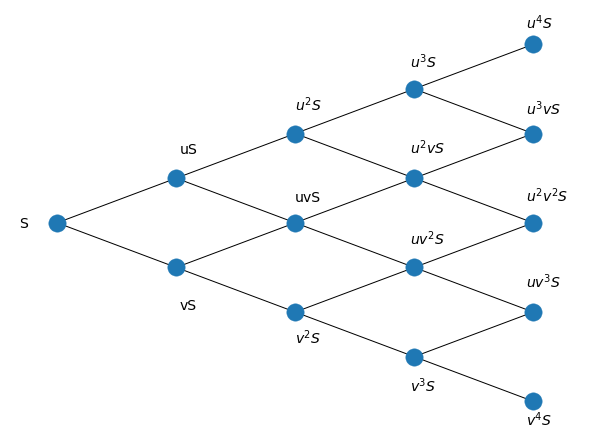

In [89]:
plot_asset_path()

## Path Probability

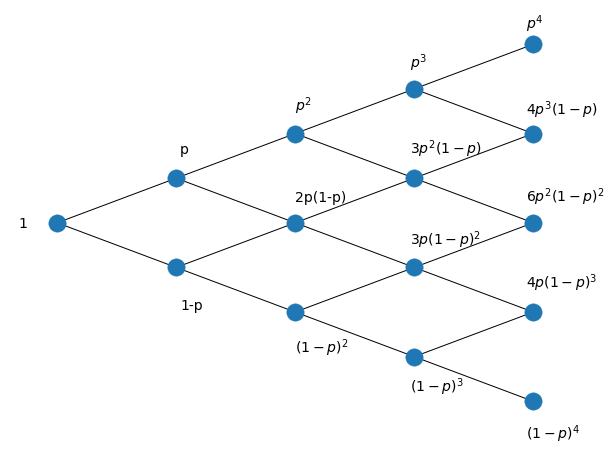

In [90]:
plot_probability()

## Risk Neutral Probability

Risk-neutral measure is a probability measure such that each share price today is the discounted expectations of the share price. From Paul's lecture, we know the formula for u, v, p′ and V are as follows,

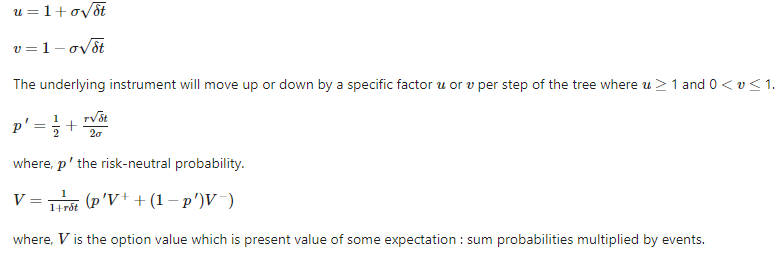

In [92]:
Image.open(os.path.join(dir_path,'RiskNeutralProb.PNG'))

## Building Binomial Tree

Next, we will build a binomial tree using the risk neutral probability. Building a tree is a multi step process which involves.

Step 1: Draw a n-step tree

Step 2: At the end of n-step, estimate terminal prices

Step 3: Calculate the option value at each node based on the terminal price, exercise price and type

Step 4: Discount it back one step, that is, from n to n-1, according to the risk neutral probability

Step 5: Repeat the previous step until we find the final value at step 0

## Binomial Pricing Model

In [15]:
def binomial_option(spot, strike,rate,sigma,time,steps,output =0):
    
    """
    binomial_option(spot, strike, rate, sigma, time, steps, output=0)
    
    Function to calculate binomial option pricing for european call option
    
    Params
    ------
    spot       -int or float    - spot price
    strike     -int or float    - strike price
    rate       -float           - interest rate
    time       -int or float    - expiration time
    steps      -int             - number of time steps
    output     -int             - [0: price, 1: payoff, 2: option value, 3: option delta]
    
    Returns
    --------
    out: ndarray
    An array object of price, payoff, option value and delta as specified by the output flag
    
    """
    # define parameters
    ts = time/steps
    u = 1 + sigma*np.sqrt(ts)
    v = 1 - sigma*np.sqrt(ts)
    p = 0.5 + rate*np.sqrt(ts)/(2*sigma)
    df = 1/(1+rate*ts)
    
    # initialize arrays
    ps = np.zeros([steps+1, steps+1])              # underlying asset price
    cp = np.zeros([steps+1, steps+1])              # call-put payoff
    V = np.zeros([steps+1, steps+1])               # option price
    d = np.zeros([steps+1, steps+1])               # delta of option
    
    # binomial loop - outer loop on columns and inner loop on rows
    # forward loop, j goes from 0 to 4, index locations 0,1,2,3,4 in 5X5 grid, i goes from 0 to j
    for j in range(steps+1):
        for i in range(j+1):
            ps[i,j] = spot*np.power(v,i)*np.power(u,j-i)
            cp[i,j] = np.maximum(ps[i,j]-strike,0)
    
    # backward loop, j goes from 5 to 1, index locations 0,1,2,3,4 in 5X5 grid
    for j in range(steps+1,0,-1):
        for i in range(j):
            if j == steps+1:
                V[i,j-1] = cp[i,j-1]
                d[i,j-1] = 0
            else:
                V[i,j-1] = p*cp[i,j] + (1-p)*cp[i+1,j]
                d[i,j-1] = (V[i,j]-V[i+1,j])/(ps[i,j]-ps[i+1,j])
                
    results = np.around(ps,2), np.around(cp,2), np.around(V,2), np.around(d,4)
    
    return results[output]
    

In [16]:
# Asset price
px = binomial_option(100,100,0.05,0.20,1,4,0)
px

array([[100.  , 110.  , 121.  , 133.1 , 146.41],
       [  0.  ,  90.  ,  99.  , 108.9 , 119.79],
       [  0.  ,   0.  ,  81.  ,  89.1 ,  98.01],
       [  0.  ,   0.  ,   0.  ,  72.9 ,  80.19],
       [  0.  ,   0.  ,   0.  ,   0.  ,  65.61]])

In [17]:
# option payoff
cp = binomial_option(100,100,0.05,0.20,1,4,1)
cp

array([[ 0.  , 10.  , 21.  , 33.1 , 46.41],
       [ 0.  ,  0.  ,  0.  ,  8.9 , 19.79],
       [ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ],
       [ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ],
       [ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ]])

In [18]:
# Option price 
opt = binomial_option(100,100,0.05,0.20,1,4,2)
opt

array([[ 5.63, 11.81, 22.51, 34.76, 46.41],
       [ 0.  ,  0.  ,  5.01, 11.13, 19.79],
       [ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ],
       [ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ],
       [ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ]])

In [19]:
# Option delta
delta = binomial_option(100,100,0.05,0.20,1,4,3)
delta

array([[0.5906, 0.7957, 0.9765, 1.    , 0.    ],
       [0.    , 0.2781, 0.5622, 0.9086, 0.    ],
       [0.    , 0.    , 0.    , 0.    , 0.    ],
       [0.    , 0.    , 0.    , 0.    , 0.    ],
       [0.    , 0.    , 0.    , 0.    , 0.    ]])

In [20]:
# Binomial Option Price
print(f"European Call Option Price using Binomial Tree Method: {opt[0,0]:.2f}")

European Call Option Price using Binomial Tree Method: 5.63


### Visualize the Binomial Tree

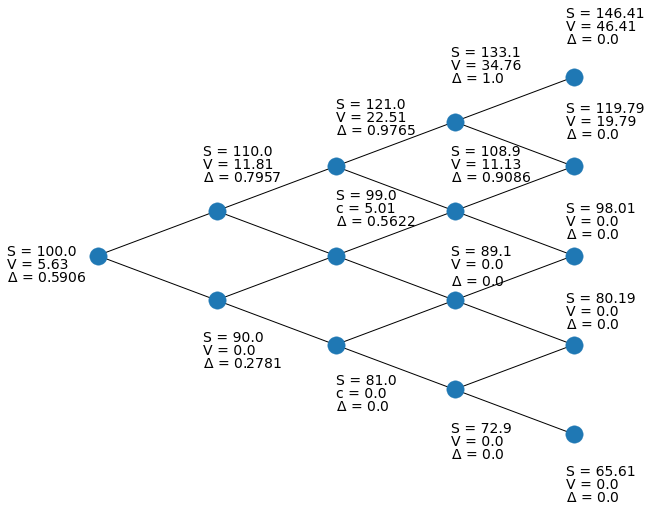

In [21]:
# Plot a 4-Step Binomial Tree 
plot_binomial_tree(px[0,0], px, opt, delta)